<img src="https://ga-curriculum.github.io/universal-resources-internal/ga-logos/ga-red-cog-72x72.png" alt="" style="float: left; margin: 20px 20px 0 0; height: 55px">

# Classification Metrics

_Authors:_ Tim Book, Matt Brems, Riley Dallas

---

In [53]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics

### Create dataset

Built-in Scikit-Learn datasets come in their own special format. You can study this on your own but it's not that interesting.

In [2]:
data = load_breast_cancer()
X = data.data
y = 1 - data.target

In [8]:
bc = pd.DataFrame(X, columns=data.feature_names)
bc['cancer'] = y
bc.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,cancer
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### Train/Test Split

**(NOW YOU):** Using random state of 42, create a train test split, standard scale the data, and carry out a 5-nearest neighbors model.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1234)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

knn = KNeighborsClassifier(5)
knn.fit(X_train_sc, y_train)

KNeighborsClassifier()

### Predictions

Create `y_pred`, our vector of predictions.

In [20]:
y_pred = knn.predict(X_test_sc)

### Confusion Matrix

We'll create a confusion matrix using the `confusion_matrix` function from `sklearn`'s `metrics` module.

In [21]:
cm = metrics.confusion_matrix(y_test, y_pred)
cm

array([[87,  1],
       [ 8, 47]])

In [22]:
# Quick trick

cm_df = pd.DataFrame(
    cm,
    columns=['pred benign', 'pred malignant'],
    index=['actual benign', 'actual malignant']
)
cm_df

,pred benign,pred malignant
actual benign,87,1
actual malignant,8,47


### Calculate...

In [23]:
# Recall / Sensitivity
47 / (47 + 8)

0.8545454545454545

In [25]:
# Precision
47 / (47 + 1)

0.9791666666666666

In [26]:
# Specificity
87 / (87 + 1)

0.9886363636363636

In [27]:
# F1 score
metrics.f1_score(y_test, y_pred)

0.912621359223301

### ROC and AUC

Let's quickly prep a new dataset and model to illustrate the ROC curve and AUC score.

In [33]:
smoking = pd.read_csv('data/Whickham.csv')

In [34]:
smoking.head()

,outcome,smoker,age
0,Alive,Yes,23
1,Alive,Yes,18
2,Dead,Yes,71
3,Alive,No,67
4,Alive,No,64


In [35]:
smoking['outcome'] = smoking['outcome'].map({'Alive': 0, 'Dead': 1})
smoking['smoker'] = smoking['smoker'].map({'Yes': 1, 'No': 0})

In [39]:
X = smoking[['smoker', 'age']]
y = smoking['outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=123)

In [42]:
lr = LogisticRegression(penalty='none')
lr.fit(X_train, y_train)
print(lr.score(X_train, y_train))
print(lr.score(X_test, y_test))

0.8416243654822335
0.8328267477203647


In [44]:
# What's this again?
lr.predict_proba(X_test)[:5]

array([[0.99350665, 0.00649335],
       [0.43363819, 0.56636181],
       [0.61589517, 0.38410483],
       [0.66767588, 0.33232412],
       [0.81118672, 0.18881328]])

In [45]:
y_pred_prob = lr.predict_proba(X_test)[:, 1]

In [47]:
# Can compute AUC immediately - nice!
metrics.roc_auc_score(y_test, y_pred_prob)

0.8950292397660818

### Displaying the ROC Curve


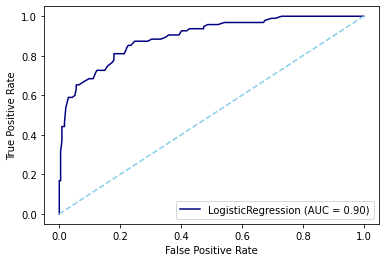

In [59]:
# Newer versions of sklearn:
# metrics.RocCurveDisplay.from_estimator(estimator = lr, X = X_test, y = y_test) 

metrics.plot_roc_curve(lr, X_test, y_test, c='navy')
plt.plot([0, 1], [0, 1], c='skyblue', linestyle='--');

# Summary

Classification metrics are necessarily different from regression metrics since we can't mathematically compute residuals. So, there are a lot of different metrics to articulate the difference between $\mathbf{y}$ and $\mathbf{\hat y}$.

Metrics covered:
1. Accuracy and misclassification rate
1. Sensitivity and specificity
1. Precision and recall
1. $F_1$ and $F_\beta$
1. AUC score

Remember that, unlike for regression, not every metric is relevant all the time. **Framing the problem is a necessary first step!** Only then can you calculate a metric to answer your research goal.